In [1]:

# ==============================
# 1. DATA HANDLING
# ==============================
import pandas as pd
import numpy as np

# ==============================
# 2. VISUALIZATION
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# 3. DATA SPLITTING & CROSS-VALIDATION
# ==============================
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold,
    GridSearchCV,
    RandomizedSearchCV
)

# ==============================
# 4. PREPROCESSING
# ==============================
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# ==============================
# 5. CLASSIFICATION MODELS
# ==============================
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

# ==============================
# 6. HYPERPARAMETER SEARCH DISTRIBUTIONS
# ==============================
from scipy.stats import randint, uniform, loguniform

# ==============================
# 7. MODEL EVALUATION
# ==============================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

# ==============================
# 8. REPRODUCIBILITY
# ==============================
RANDOM_STATE = 42

print("All imports completed successfully!")


All imports completed successfully!


In [2]:
# Load dataset
df = pd.read_csv("D:\\EDA projects\\amazon-marketplace-analytics\\data\\amazon_employee_eda_model_assignment.csv")

# Basic validation
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["returned_flag"].value_counts())

print("\nTarget percentage:")
print((df["returned_flag"].value_counts(normalize=True) * 100).round(2))

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (100120, 30)

First 5 rows:


,order_id,order_date,customer_id,product_id,product_name,category,city,state,quantity,unit_price_inr,...,review_length_words,payment_method,fulfillment_by,delivery_days,shipping_speed,returned,order_status,order_month,order_year,returned_flag
0,ORD000000001,2025-01-20,U0044721,P010606,Bluetooth Speaker,Electronics,Ahmedabad,Gujarat,1,2754.51,...,4,Debit Card,Amazon,4.0,Standard,No,Delivered,1,2025,0
1,ORD000000002,2026-05-11,U0023488,P007316,Yoga Mat,Sports,Kolkata,West Bengal,1,1772.76,...,2,Credit Card,Third-party Seller,2.0,Fast,No,Delivered,5,2026,0
2,ORD000000003,2026-06-02,U0026345,P000513,Bluetooth Speaker,Electronics,Haldwani,Uttarakhand,2,1375.71,...,4,Credit Card,Amazon,4.0,Standard,No,Delivered,6,2026,0
3,ORD000000004,2026-02-08,U0032504,P011543,Shampoo,Beauty,Chennai,Tamil Nadu,1,978.28,...,4,Net Banking,Third-party Seller,1.0,Fast,No,Delivered,2,2026,0
4,ORD000000005,2026-02-22,U0025525,P005429,Shampoo,Beauty,Moradabad,Uttar Pradesh,2,817.15,...,4,Cash on Delivery,Amazon,2.0,Fast,No,Delivered,2,2026,0



Column names:
['order_id', 'order_date', 'customer_id', 'product_id', 'product_name', 'category', 'city', 'state', 'quantity', 'unit_price_inr', 'discount_percent', 'discounted_price_inr', 'total_amount_inr', 'rating', 'review_text', 'sentiment_label', 'verified_purchase', 'helpful_votes', 'total_votes', 'helpful_ratio', 'review_length_words', 'payment_method', 'fulfillment_by', 'delivery_days', 'shipping_speed', 'returned', 'order_status', 'order_month', 'order_year', 'returned_flag']

Target distribution:
returned_flag
0    93107
1     7013
Name: count, dtype: int64

Target percentage:
returned_flag
0    93.0
1     7.0
Name: proportion, dtype: float64

Missing values:
review_text         3464
rating              2538
delivery_days       2021
discount_percent    1444
payment_method      1205
city                 865
category               0
product_name           0
product_id             0
state                  0
dtype: int64

Duplicate rows: 120


In [3]:
# Target column
target = "returned_flag"

# Columns that could leak the target or act as identifiers
drop_cols = [
    "returned_flag",
    "returned",
    "order_status",
    "review_text",
    "rating",
    "delivery_days",
    "order_id",
    "customer_id",
    "product_id",
    "order_date"
]

# Separate features and target
X = df.drop(columns=drop_cols, errors="ignore")
y = df[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True).mul(100).round(2))

print("\nNumeric features:", X.select_dtypes(include=np.number).columns.tolist())
print("\nCategorical features:", X.select_dtypes(exclude=np.number).columns.tolist())

Features shape: (100120, 20)
Target shape: (100120,)

Target distribution:
returned_flag
0    93.0
1     7.0
Name: proportion, dtype: float64

Numeric features: ['quantity', 'unit_price_inr', 'discount_percent', 'discounted_price_inr', 'total_amount_inr', 'helpful_votes', 'total_votes', 'helpful_ratio', 'review_length_words', 'order_month', 'order_year']

Categorical features: ['product_name', 'category', 'city', 'state', 'sentiment_label', 'verified_purchase', 'payment_method', 'fulfillment_by', 'shipping_speed']


In [4]:
# Separate training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution (%):")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training features: (80096, 20)
Testing features: (20024, 20)

Training target distribution (%):
returned_flag
0    93.0
1     7.0
Name: proportion, dtype: float64

Testing target distribution (%):
returned_flag
0    92.99
1     7.01
Name: proportion, dtype: float64


In [5]:
# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("\nPreprocessing pipeline created successfully!")

Numerical features: 11
Categorical features: 9

Preprocessing pipeline created successfully!


# Baseline Model

In [6]:
# Create baseline model
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

# Train the baseline
baseline_model.fit(X_train, y_train)

# Make predictions
y_pred_baseline = baseline_model.predict(X_test)

# Evaluate
print("BASELINE MODEL RESULTS")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_baseline), 4))

print("Precision:", round(
    precision_score(y_test, y_pred_baseline, zero_division=0), 4
))

print("Recall:", round(
    recall_score(y_test, y_pred_baseline, zero_division=0), 4
))

print("F1 Score:", round(
    f1_score(y_test, y_pred_baseline, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, zero_division=0))

BASELINE MODEL RESULTS
-----------------------------------
Accuracy: 0.9299
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96     18621
           1       0.00      0.00      0.00      1403

    accuracy                           0.93     20024
   macro avg       0.46      0.50      0.48     20024
weighted avg       0.86      0.93      0.90     20024



# Logistic Regression

In [7]:
# Create Logistic Regression pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# Train model
lr_model.fit(X_train, y_train)

# Predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluate model
print("LOGISTIC REGRESSION RESULTS")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(
    precision_score(y_test, y_pred_lr, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred_lr, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, y_pred_lr, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

LOGISTIC REGRESSION RESULTS
-----------------------------------
Accuracy: 0.9299
Precision: 0.0
Recall: 0.0
F1 Score: 0.0

Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.96     18621
           1       0.00      0.00      0.00      1403

    accuracy                           0.93     20024
   macro avg       0.46      0.50      0.48     20024
weighted avg       0.86      0.93      0.90     20024


Confusion Matrix:
[[18621     0]
 [ 1403     0]]


## Class Imbalance

In [8]:
# Logistic Regression with balanced class weights
lr_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# Train
lr_balanced.fit(X_train, y_train)

# Predict
y_pred_balanced = lr_balanced.predict(X_test)

# Evaluate
print("BALANCED LOGISTIC REGRESSION")
print("-" * 40)

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced), 4
))
print("Precision:", round(
    precision_score(y_test, y_pred_balanced, zero_division=0), 4
))
print("Recall:", round(
    recall_score(y_test, y_pred_balanced, zero_division=0), 4
))
print("F1 Score:", round(
    f1_score(y_test, y_pred_balanced, zero_division=0), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_balanced))

BALANCED LOGISTIC REGRESSION
----------------------------------------
Accuracy: 0.5163
Precision: 0.0708
Recall: 0.4868
F1 Score: 0.1236

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.52      0.67     18621
           1       0.07      0.49      0.12      1403

    accuracy                           0.52     20024
   macro avg       0.50      0.50      0.39     20024
weighted avg       0.87      0.52      0.63     20024


Confusion Matrix:
[[9655 8966]
 [ 720  683]]


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import pandas as pd

models = {
    "Dummy Baseline": (baseline_model, y_pred_baseline),
    "Logistic Regression": (lr_model, y_pred_lr),
    "Balanced Logistic Regression": (
        lr_balanced, y_pred_balanced
    )
}

results = []

for name, (model, predictions) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

comparison_df = pd.DataFrame(results)

display(
    comparison_df.round(4).sort_values(
        by="F1 Score", ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1 Score
2,Balanced Logistic Regression,0.5163,0.0708,0.4868,0.1236
0,Dummy Baseline,0.9299,0.0000,0.0000,0.0000
1,Logistic Regression,0.9299,0.0000,0.0000,0.0000


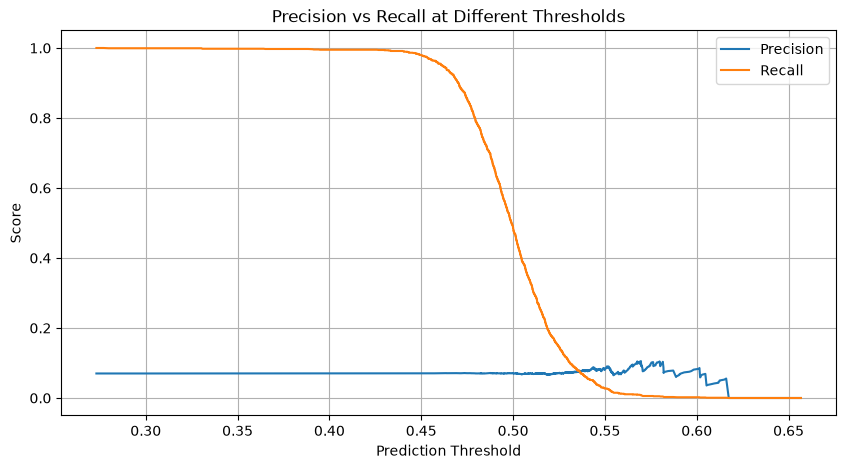

Average Precision: 0.0712


In [10]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)
import matplotlib.pyplot as plt

# Get probability of class 1 (returned)
y_prob = lr_balanced.predict_proba(X_test)[:, 1]

# Precision-recall values at different thresholds
precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

# Plot precision and recall against thresholds
plt.figure(figsize=(10, 5))
plt.plot(thresholds, precision[:-1], label="Precision")
plt.plot(thresholds, recall[:-1], label="Recall")

plt.xlabel("Prediction Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall at Different Thresholds")
plt.legend()
plt.grid(True)
plt.show()

print(
    "Average Precision:",
    round(average_precision_score(y_test, y_prob), 4)
)

In [11]:
# Compare predicted probabilities by actual class
probability_check = pd.DataFrame({
    "Actual_Return": y_test.to_numpy(),
    "Predicted_Probability": y_prob
})

print("Predicted probability by actual class:\n")

display(
    probability_check.groupby("Actual_Return")[
        "Predicted_Probability"
    ].agg(["count", "mean", "median", "std"]).round(4)
)

print("\nProbability quantiles:")
display(
    probability_check.groupby("Actual_Return")[
        "Predicted_Probability"
    ].quantile([0.10, 0.25, 0.50, 0.75, 0.90]).unstack().round(4)
)

Predicted probability by actual class:



,count,mean,median,std
Actual_Return,,,,
0,18621,0.4989,0.4988,0.0271
1,1403,0.4994,0.4991,0.0267



Probability quantiles:


,0.10,0.25,0.50,0.75,0.90
Actual_Return,,,,,
0,0.4684,0.483,0.4988,0.5152,0.5305
1,0.4702,0.483,0.4991,0.5151,0.5310


In [12]:
# Check how the target relates to available features
print("Target distribution:")
print(df["returned_flag"].value_counts(normalize=True).round(4))

print("\nTarget correlation with numeric features:")
numeric_corr = (
    df.select_dtypes(include=np.number)
    .corr(numeric_only=True)["returned_flag"]
    .drop("returned_flag")
    .sort_values(key=abs, ascending=False)
)

display(numeric_corr.head(15).to_frame("Correlation"))

Target distribution:
returned_flag
0    0.93
1    0.07
Name: proportion, dtype: float64

Target correlation with numeric features:


,Correlation
total_amount_inr,-0.005726
unit_price_inr,-0.004871
discount_percent,-0.004549
discounted_price_inr,-0.003893
helpful_ratio,-0.003681
rating,-0.003169
quantity,-0.002927
total_votes,-0.002874
order_month,-0.002518
review_length_words,-0.002212


In [13]:
categorical_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

for col in categorical_cols:
    summary = (
        df.groupby(col, dropna=False)["returned_flag"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
    )

    summary["return_rate_percent"] = (summary["mean"] * 100).round(2)

    print(f"\nFeature: {col}")
    display(summary.drop(columns="mean").head(10))


Feature: product_name


,count,return_rate_percent
product_name,,
Programming Book,6333,7.37
Yoga Mat,6323,7.35
Bluetooth Speaker,6357,7.27
Coffee,6328,7.22
Paperback Novel,6263,7.17
Smart Watch,6288,7.09
Cotton T-Shirt,6188,7.08
Water Bottle,6241,6.99
Running Shoes,6189,6.98



Feature: category


,count,return_rate_percent
category,,
Books,12596,7.27
Grocery,6328,7.22
Sports,12481,7.07
Electronics,18840,7.05
Fashion,12377,7.03
Home & Kitchen,18755,6.92
Toys & Games,6123,6.73
Beauty,12620,6.73



Feature: city


...

,count,return_rate_percent
payment_method,,
Net Banking,7915,7.62
UPI,34516,7.15
Credit Card,24754,6.89
Debit Card,17931,6.81
Cash on Delivery,13799,6.78
NaN,1205,6.64



Feature: fulfillment_by


,count,return_rate_percent
fulfillment_by,,
Third-party Seller,28048,7.38
Amazon,72072,6.86



Feature: shipping_speed


,count,return_rate_percent
shipping_speed,,
Fast,62311,7.06
Standard,28802,6.91
Slow,9007,6.89


In [14]:
# Check relationship between the two target columns
print("returned_flag vs returned:")
print(pd.crosstab(df["returned_flag"], df["returned"]))

print("\nUnique values in returned_flag:")
print(df["returned_flag"].value_counts(dropna=False))

print("\nUnique values in returned:")
print(df["returned"].value_counts(dropna=False))

print(
    "\nAre both columns identical?",
    df["returned_flag"].equals(df["returned"])
)

returned_flag vs returned:
returned          No   Yes
returned_flag             
0              93107     0
1                  0  7013

Unique values in returned_flag:
returned_flag
0    93107
1     7013
Name: count, dtype: int64

Unique values in returned:
returned
No     93107
Yes     7013
Name: count, dtype: int64

Are both columns identical? False


In [15]:
print("returned_flag dtype:", df["returned_flag"].dtype)
print("returned dtype:", df["returned"].dtype)

print("\nValue mapping:")
print(
    (df["returned_flag"] == 0).equals(df["returned"].eq("No"))
)
print(
    (df["returned_flag"] == 1).equals(df["returned"].eq("Yes"))
)

returned_flag dtype: int64
returned dtype: str

Value mapping:
True
True


In [16]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# Use the existing X_train and y_train
X_mi = X_train.copy()

# Convert categorical columns into integer codes
for col in X_mi.select_dtypes(
    include=["object", "category"]
).columns:
    X_mi[col] = (
        LabelEncoder()
        .fit_transform(
            X_mi[col].fillna("Missing").astype(str)
        )
    )

# Fill missing numeric values
X_mi = X_mi.fillna(X_mi.median())

# Measure feature information about the target
mi_scores = mutual_info_classif(
    X_mi,
    y_train,
    random_state=42
)

mi_results = (
    pd.DataFrame({
        "Feature": X_mi.columns,
        "Mutual_Information": mi_scores
    })
    .sort_values(
        "Mutual_Information",
        ascending=False
    )
)

mi_results.head(15)

C:\Users\awara\AppData\Local\Temp\ipykernel_27484\667584117.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in X_mi.select_dtypes(


,Feature,Mutual_Information
10,verified_purchase,0.013493
9,sentiment_label,0.010821
19,order_year,0.007290
4,quantity,0.007039
17,shipping_speed,0.003865
16,fulfillment_by,0.003268
15,payment_method,0.003145
13,helpful_ratio,0.002827
6,discount_percent,0.002526
11,helpful_votes,0.002485


In [17]:
features_to_check = [
    "verified_purchase",
    "sentiment_label",
    "order_year",
    "quantity",
    "shipping_speed",
    "fulfillment_by"
]

for col in features_to_check:
    print(f"\n--- {col} ---")

    result = (
        df.groupby(col, dropna=False)["returned_flag"]
        .agg(["count", "mean"])
        .sort_values("mean", ascending=False)
    )

    result["return_rate_percent"] = (
        result["mean"] * 100
    ).round(2)

    print(
        result[["count", "return_rate_percent"]]
        .to_string()
    )


--- verified_purchase ---
                   count  return_rate_percent
verified_purchase                            
Yes                82246                 7.04
No                 17874                 6.85

--- sentiment_label ---
                 count  return_rate_percent
sentiment_label                            
Negative         14269                 7.24
Neutral          15878                 6.99
Positive         69973                 6.96

--- order_year ---
            count  return_rate_percent
order_year                            
2025        35663                 7.04
2024        36102                 7.00
2026        28355                 6.97

--- quantity ---
          count  return_rate_percent
quantity                            
4          2892                 7.37
1         67890                 7.10
5           978                 6.85
3          8043                 6.81
2         20317                 6.72

--- shipping_speed ---
                count  retur

In [18]:
from scipy.stats import chi2_contingency
import pandas as pd

categorical_cols = [
    "verified_purchase",
    "sentiment_label",
    "shipping_speed",
    "fulfillment_by",
    "payment_method",
    "category",
    "city",
    "state"
]

results = []

for col in categorical_cols:
    table = pd.crosstab(df[col], df["returned_flag"])
    chi2, p_value, dof, expected = chi2_contingency(table)

    n = table.to_numpy().sum()
    min_dim = min(table.shape[0] - 1, table.shape[1] - 1)

    cramers_v = (
        (chi2 / (n * min_dim)) ** 0.5
        if min_dim > 0 else 0
    )

    results.append({
        "Feature": col,
        "P_value": p_value,
        "Cramers_V": cramers_v
    })

chi_results = (
    pd.DataFrame(results)
    .sort_values("Cramers_V", ascending=False)
)

chi_results

,Feature,P_value,Cramers_V
6,city,0.638642,0.011235
7,state,0.680744,0.010074
4,payment_method,0.083758,0.009117
3,fulfillment_by,0.004188,0.009050
5,category,0.726484,0.006668
1,sentiment_label,0.489594,0.003777
2,shipping_speed,0.648466,0.002942
0,verified_purchase,0.391494,0.002708


In [19]:
# Check return rates across feature combinations

combo_features = [
    "quantity",
    "discount_percent",
    "delivery_days",
    "product_name"
]

combo_df = df[combo_features + ["returned_flag"]].copy()

# Group numeric values into ranges to avoid too many groups
combo_df["quantity_group"] = combo_df["quantity"].astype(str)

combo_df["discount_group"] = pd.cut(
    combo_df["discount_percent"],
    bins=[-1, 0, 10, 20, 30, 50, 100],
    include_lowest=True
)

combo_df["delivery_group"] = pd.cut(
    combo_df["delivery_days"],
    bins=[-1, 3, 5, 7, 10, 100],
    include_lowest=True
)

combo_results = (
    combo_df.groupby(
        [
            "product_name",
            "quantity_group",
            "discount_group",
            "delivery_group"
        ],
        observed=True
    )["returned_flag"]
    .agg(["count", "mean"])
    .reset_index()
)

# Ignore tiny groups to reduce misleading extremes
combo_results = combo_results[
    combo_results["count"] >= 100
].copy()

combo_results["return_rate_percent"] = (
    combo_results["mean"] * 100
).round(2)

combo_results.sort_values(
    "return_rate_percent",
    ascending=False
).head(15)

,product_name,quantity_group,discount_group,delivery_group,count,mean,return_rate_percent
1035,Running Shoes,1,"(20.0, 30.0]","(3.0, 5.0]",116,0.146552,14.66
242,Coffee,2,"(20.0, 30.0]","(-1.001, 3.0]",100,0.130000,13.00
1238,Smart Watch,1,"(20.0, 30.0]","(3.0, 5.0]",122,0.106557,10.66
30,Bluetooth Speaker,2,"(0.0, 10.0]","(-1.001, 3.0]",254,0.106299,10.63
510,Dumbbell Set,1,"(-1.001, 0.0]","(3.0, 5.0]",190,0.105263,10.53
7,Bluetooth Speaker,1,"(0.0, 10.0]","(5.0, 7.0]",105,0.104762,10.48
625,Face Moisturizer,1,"(10.0, 20.0]","(3.0, 5.0]",308,0.100649,10.06
320,Cotton T-Shirt,1,"(10.0, 20.0]","(5.0, 7.0]",101,0.099010,9.90
740,Mixer Grinder,2,"(-1.001, 0.0]","(-1.001, 3.0]",174,0.097701,9.77
1526,Yoga Mat,1,"(-1.001, 0.0]","(3.0, 5.0]",197,0.096447,9.64


In [20]:
# Overall return-rate distribution across sufficiently large groups

print("Number of groups:", len(combo_results))

print("\nReturn-rate summary:")
print(
    combo_results["return_rate_percent"]
    .describe()
    .round(2)
)

print("\nGroups with at least 100 records:")
print(
    "Above 10% return rate:",
    (combo_results["return_rate_percent"] > 10).sum()
)

print(
    "Above 7% return rate:",
    (combo_results["return_rate_percent"] > 7).sum()
)

print(
    "At or below 7% return rate:",
    (combo_results["return_rate_percent"] <= 7).sum()
)

Number of groups: 230

Return-rate summary:
count    230.00
mean       6.88
std        1.78
min        0.99
25%        5.80
50%        6.91
75%        7.91
max       14.66
Name: return_rate_percent, dtype: float64

Groups with at least 100 records:
Above 10% return rate: 7
Above 7% return rate: 110
At or below 7% return rate: 120
